In [1]:
import warnings
warnings.filterwarnings("ignore", category=Warning)

#Pull in the libraries we need
import numpy as np
import pandas as pd
from sklearn.datasets import load_diabetes

#New libraries for access to model selection tasks
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression #OLS ... vs SGDRegressor for Gradient Descent
from sklearn.metrics import mean_squared_error, r2_score

#Pull in the plotting library and specify to display inline/static images
import matplotlib.pyplot as plt

In [2]:
diabetesRaw = load_diabetes()
X = pd.DataFrame(diabetesRaw.data, columns=diabetesRaw.feature_names)
y = pd.Series(diabetesRaw.target)
X.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


In [3]:
y

0      151.0
1       75.0
2      141.0
3      206.0
4      135.0
       ...  
437    178.0
438    104.0
439    132.0
440    220.0
441     57.0
Length: 442, dtype: float64

In [4]:
print(diabetesRaw.DESCR)

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

  :Number of Instances: 442

  :Number of Attributes: First 10 columns are numeric predictive values

  :Target: Column 11 is a quantitative measure of disease progression one year after baseline

  :Attribute Information:
      - age     age in years
      - sex
      - bmi     body mass index
      - bp      average blood pressure
      - s1      tc, total serum cholesterol
      - s2      ldl, low-density lipoproteins
      - s3      hdl, high-density lipoproteins
      - s4      tch, total cholesterol / HDL
      - s5      ltg, possibly log of serum triglycerides level
      - s6      glu, blood sugar level

Note: Each of these 1

In [5]:
#Split the dataset into training and testing sets with 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [6]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [7]:
#Make predictions on the testing set
y_hat = model.predict(X_test)

In [8]:
# Evaluate the model
mse = mean_squared_error(y_test, y_hat)
r2 = r2_score(y_test, y_hat)

In [9]:
#Measures the average of the squared prediction errors — how far off the model’s predictions are overall.
print(f"Mean Squared Error: {mse}")

#Shows the average prediction error in the same units as the target variable — smaller means better.
print(f"Root Mean Squared Error: {np.sqrt(mse)}")

#Indicates how much of the variation in the data is explained by the model — higher means a better fit.
print(f"R-squared: {r2}")

Mean Squared Error: 2900.193628493483
Root Mean Squared Error: 53.85344583676594
R-squared: 0.45260276297191915


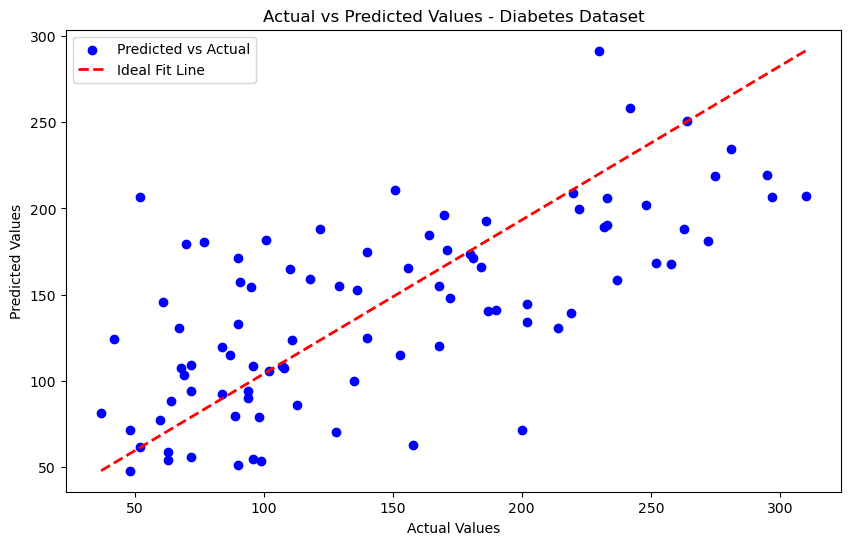

In [18]:
# Plotting actual vs. predicted values
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_hat, color='blue', label='Predicted vs Actual')
plt.plot([y_test.min(), y_test.max()], [y_hat.min(), y_hat.max()], 'r--', lw=2, label='Ideal Fit Line')



plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Actual vs Predicted Values - Diabetes Dataset')
plt.legend()
plt.show()

In [19]:
coef = pd.Series(
    model.coef_,
    index=X.columns
)

print("Intercept:", model.intercept_)
print(coef)

Intercept: 151.34560453985995
age     37.904021
sex   -241.964362
bmi    542.428759
bp     347.703844
s1    -931.488846
s2     518.062277
s3     163.419983
s4     275.317902
s5     736.198859
s6      48.670657
dtype: float64


In [20]:
import statsmodels.api as sm

X_train_sm = sm.add_constant(X_train)

ols_model = sm.OLS(y_train, X_train_sm)
results = ols_model.fit()

print(results.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.528
Model:                            OLS   Adj. R-squared:                  0.514
Method:                 Least Squares   F-statistic:                     38.25
Date:                Mon, 21 Sep 2026   Prob (F-statistic):           5.41e-50
Time:                        12:55:33   Log-Likelihood:                -1906.1
No. Observations:                 353   AIC:                             3834.
Df Residuals:                     342   BIC:                             3877.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        151.3456      2.902     52.155      0.0

## Interaction term: effect of one feature depends on other

In [25]:
import statsmodels.formula.api as smf

In [26]:
train_df = X_train.copy()
train_df['y'] = y_train.values

In [27]:
train_df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,y
17,0.070769,0.050680,0.012117,0.056301,0.034206,0.049416,-0.039719,0.034309,0.027364,-0.001078,144.0
66,-0.009147,0.050680,-0.018062,-0.033213,-0.020832,0.012152,-0.072854,0.071210,0.000272,0.019633,150.0
137,0.005383,-0.044642,0.049840,0.097615,-0.015328,-0.016345,-0.006584,-0.002592,0.017036,-0.013504,280.0
245,-0.027310,-0.044642,-0.035307,-0.029770,-0.056607,-0.058620,0.030232,-0.039493,-0.049872,-0.129483,125.0
31,-0.023677,-0.044642,-0.065486,-0.081413,-0.038720,-0.053610,0.059685,-0.076395,-0.037129,-0.042499,59.0


<p>For demonstration purpose, I assume effect of age and bmi depends on each other</p>
<p>
  <i>y</i> = &beta;<sub>0</sub> + &beta;<sub>1</sub><i>age</i> + &beta;<sub>2</sub><i>bmi</i> + &hellip; + &beta;<sub>10</sub><i>s6</i> + &beta;<sub>11</sub>(<i>age</i> &times; <i>bmi</i>) + &epsilon;
</p>

<p>So, we're asking, does the relationship between age and diabetes outcome (y) depend on BMI?</p>

<p><strong>Mathematically:</strong></p>

<p>
  <sup>&part;<i>y</i></sup>&frasl;<sub>&part;<i>age</i></sub> = 
  &beta;<sub>age</sub> + &beta;<sub>age:bmi</sub>(<i>bmi</i>)
</p>

<p>
  If:<br>
  &beta;<sub>age</sub> = 30, &emsp; &beta;<sub>age:bmi</sub> = 1.5
</p>

<p>
  then at <strong>BMI = 20</strong>:<br>
  <sup>&part;<i>y</i></sup>&frasl;<sub>&part;<i>age</i></sub> = 30 + 1.5(20) = 60
</p>

<p>
  while at <strong>BMI = 30</strong>:<br>
  <sup>&part;<i>y</i></sup>&frasl;<sub>&part;<i>age</i></sub> = 30 + 1.5(30) = 75
</p>

<p>So the estimated association between age and the outcome changes depending on BMI.</p>

In [30]:
model = smf.ols(
    'y ~ age + sex + bmi + bp + s1+ s2 + s3 + s4 + s5 + s6 + (age*bmi)', # That's how you can define your own equation
    data=train_df
).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.530
Model:                            OLS   Adj. R-squared:                  0.514
Method:                 Least Squares   F-statistic:                     34.90
Date:                Tue, 22 Sep 2026   Prob (F-statistic):           1.92e-49
Time:                        09:48:31   Log-Likelihood:                -1905.5
No. Observations:                 353   AIC:                             3835.
Df Residuals:                     341   BIC:                             3881.
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    150.7273      2.956     50.995      0.0